# RED & WHITE SKILL EDUCATION — DEEP LEARNING PR 5
## Sentiment Analysis with SimpleRNN, LSTM and GRU

**Dataset:** `IMDB Dataset.csv` (50,000 raw reviews)  
**Task:** Binary sentiment classification — negative = 0, positive = 1.  
**Framework:** TensorFlow/Keras, scikit-learn, pandas, NumPy, Matplotlib and Seaborn.

> Run from top to bottom. The full experiments can take several hours on CPU. Set `RUN_EXPENSIVE_EXPERIMENTS = False` to skip the extra sequence-length, high-learning-rate, gradient-comparison and hidden-unit sensitivity sweeps while completing the main models. The core training pipeline is kept faithful to the brief. This notebook saves figures to `plots/`.

## Reproducibility and imports
**Objective:** Load libraries, set seeds and prepare output folders. **Expected output:** versions and output directory ready.

In [1]:
import os, re, time, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, SimpleRNN, LSTM, GRU, RepeatVector, Lambda
from tensorflow.keras.callbacks import EarlyStopping, Callback
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_fscore_support)
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
PLOTS = Path('plots'); PLOTS.mkdir(exist_ok=True)
DATA_PATH = 'IMDB Dataset.csv'
MAX_WORDS, EMBED_DIM, MAXLEN = 10000, 32, 250
BATCH_SIZE, EPOCHS = 64, 15
RUN_EXPENSIVE_EXPERIMENTS = False  # set True to run every extended experiment in Tasks 4 and 6
print('TensorFlow:', tf.__version__)
print('Dataset path:', DATA_PATH, '| plots:', PLOTS.resolve())

TensorFlow: 2.21.0
Dataset path: IMDB Dataset.csv | plots: D:\deep learning\pr 5\plots


## Task 1 — Text loading, cleaning, tokenisation and padding
**Objective:** Inspect the raw data, remove duplicates, clean text and build padded integer sequences.  
**Expected output:** Stratified train/test sets with shape `(n, MAXLEN)` and a fitted training-only tokenizer.

Duplicates must be removed **before** splitting: otherwise an identical review can appear in both train and test sets and inflate test performance (data leakage). We preserve apostrophes because contractions and negation matter, and we do not remove stop-words: words such as *not* and *no* can reverse sentiment.

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
display(df.head())
print('\nSentiment counts:\n', df['sentiment'].value_counts())
print('\nNull counts:\n', df.isnull().sum())
print('\nTwo raw reviews:')
for i in range(min(2, len(df))):
    print(f'--- Review {i+1} ---\n{df.loc[i, "review"]}\n')

Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Sentiment counts:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Null counts:
 review       0
sentiment    0
dtype: int64

Two raw reviews:
--- Review 1 ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christ

In [3]:
rows_before = len(df)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicates:', duplicate_count, '| rows before:', rows_before, '| rows after:', len(df))

Duplicates: 418 | rows before: 50000 | rows after: 49582


BEFORE:
 One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due t

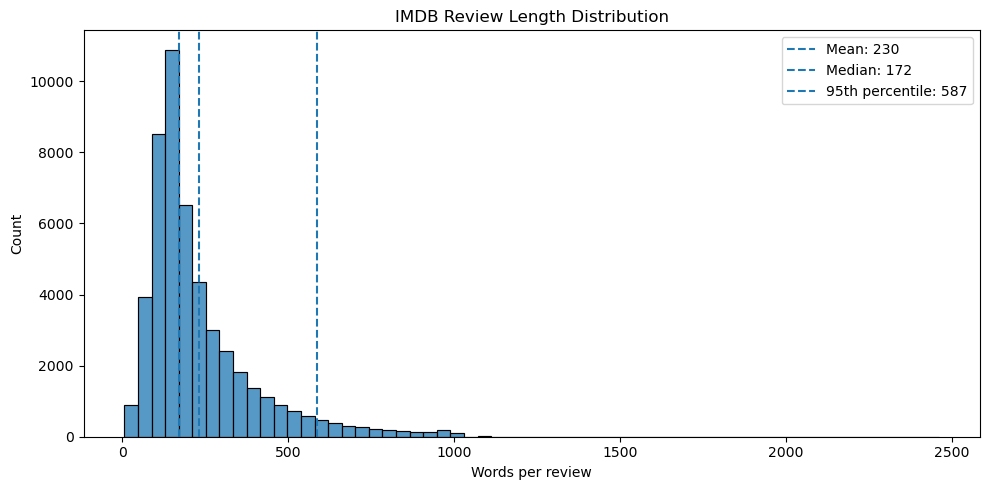

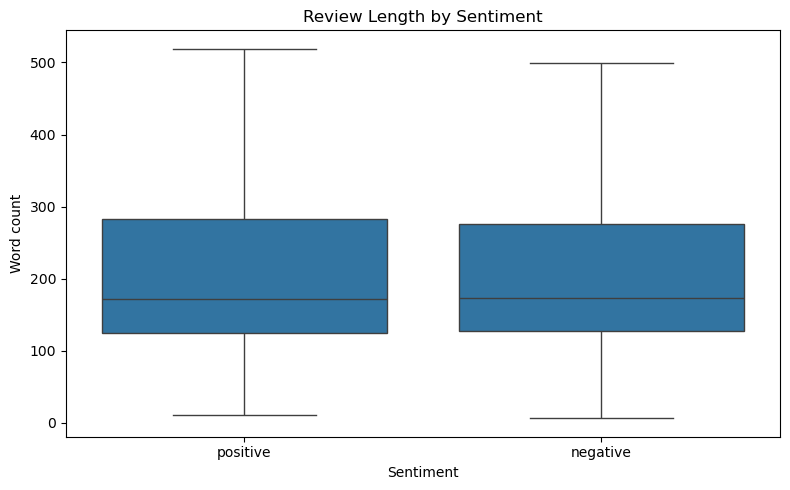

Chosen MAXLEN (95th percentile rounded to 25, capped at 500): 500


In [4]:
def clean_text(s):
    s = str(s).lower()
    s = re.sub(r'<.*?>', ' ', s)             # remove HTML
    s = re.sub(r"[^a-zA-Z']", ' ', s)       # retain letters and apostrophes
    s = re.sub(r'\s+', ' ', s).strip()
    return s

raw_example = df.loc[0, 'review']
print('BEFORE:\n', raw_example[:1000])
print('\nAFTER:\n', clean_text(raw_example)[:1000])
df['clean_review'] = df['review'].map(clean_text)
df['word_count'] = df['clean_review'].str.split().str.len()
print(df['word_count'].describe(percentiles=[.5, .9, .95]))
mean_len, median_len, p95_len = df['word_count'].mean(), df['word_count'].median(), df['word_count'].quantile(.95)
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['word_count'], bins=60, ax=ax)
for x, label in [(mean_len,'Mean'),(median_len,'Median'),(p95_len,'95th percentile')]:
    ax.axvline(x, linestyle='--', label=f'{label}: {x:.0f}')
ax.set(title='IMDB Review Length Distribution', xlabel='Words per review', ylabel='Count'); ax.legend()
fig.tight_layout(); fig.savefig(PLOTS/'length_distribution.png', dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='sentiment', y='word_count', ax=ax, showfliers=False)
ax.set(title='Review Length by Sentiment', xlabel='Sentiment', ylabel='Word count')
fig.tight_layout(); fig.savefig(PLOTS/'length_by_sentiment.png', dpi=150); plt.show()
MAXLEN = int(np.ceil(p95_len / 25) * 25)
MAXLEN = max(50, min(MAXLEN, 500))
print('Chosen MAXLEN (95th percentile rounded to 25, capped at 500):', MAXLEN)

### Task 1.5–1.7 — Split first, then fit tokenizer
We split **before** fitting the tokenizer to avoid vocabulary leakage from test reviews. `num_words=10000` limits rare-word noise and model vocabulary size. `<OOV>` maps unseen/rare tokens to a known ID. Pre-padding places zeros before the review, so the final recurrent state can be driven by the real words at the end of the sequence. Pre-truncation retains the end of very long reviews; this is a trade-off worth noting.

In [5]:
y = (df['sentiment'].str.lower() == 'positive').astype('int32').to_numpy()
texts = df['clean_review'].fillna('').to_numpy()
X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, random_state=42, stratify=y
)
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)
train_seq = tokenizer.texts_to_sequences(X_train_text)
test_seq = tokenizer.texts_to_sequences(X_test_text)
X_train = pad_sequences(train_seq, maxlen=MAXLEN, padding='pre', truncating='pre')
X_test = pad_sequences(test_seq, maxlen=MAXLEN, padding='pre', truncating='pre')
print('X_train:', X_train.shape, 'y_train:', y_train.shape)
print('X_test:', X_test.shape, 'y_test:', y_test.shape)
print('Top 10 words:', sorted(tokenizer.word_index.items(), key=lambda kv: kv[1])[:10])
print('Example sequence:', train_seq[0][:60])

X_train: (39665, 500) y_train: (39665,)
X_test: (9917, 500) y_test: (9917,)
Top 10 words: [('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('in', 8), ('it', 9), ('i', 10)]
Example sequence: [10, 234, 27, 5, 1, 4935, 3, 10, 81, 158, 8, 32, 1, 454, 2767, 7929, 121, 2, 151, 10, 25, 105, 83, 705, 35, 1, 3781, 6, 547, 1, 25, 6453, 1909, 1, 20, 547, 1417, 1, 3, 25, 105, 438, 4986, 428, 605, 1742, 35, 1, 8533, 31, 1, 547, 10, 25, 81, 548, 438, 1, 4935, 109]


**Why this is sequential:** “the movie was not good” and “the movie was good, not bad” contain overlapping vocabulary but different word order and negation. A bag-of-words representation ignores order; a recurrent model reads the tokens in sequence.

## Task 2 — RNN intuition, ANN vs RNN and forward propagation
**Objective:** Build an order-blind ANN baseline, implement an RNN cell in NumPy, and verify it against Keras.  
**Expected output:** Baseline metrics, hidden-state heatmap, and `np.allclose(...) == True`.

The ANN uses each sequence position as a separate slot after `Flatten`, so its dense layer does not share a word-position transformation across time. Its parameter count grows with `MAXLEN`.

In [6]:
def timed_fit(model, X, y, epochs=5, validation_split=0.1, callbacks=None, batch_size=BATCH_SIZE, verbose=1):
    class EpochTimer(Callback):
        def on_train_begin(self, logs=None): self.epoch_seconds=[]
        def on_epoch_begin(self, epoch, logs=None): self.t0=time.time()
        def on_epoch_end(self, epoch, logs=None): self.epoch_seconds.append(time.time()-self.t0)
    timer = EpochTimer()
    cb = [timer] + (callbacks or [])
    hist = model.fit(X, y, epochs=epochs, batch_size=batch_size, validation_split=validation_split,
                     callbacks=cb, verbose=verbose)
    return hist, timer.epoch_seconds

ann = Sequential([Input(shape=(MAXLEN,)), Embedding(MAX_WORDS, EMBED_DIM), Flatten(),
                  Dense(64, activation='relu'), Dense(1, activation='sigmoid')], name='ANN_baseline')
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
ann.summary()
ann_history, ann_times = timed_fit(ann, X_train, y_train, epochs=5)
ann_prob = ann.predict(X_test, batch_size=256, verbose=0).ravel()
ann_pred = (ann_prob >= .5).astype(int)
ann_metrics = {'Parameters': ann.count_params(), 'Time per Epoch (s)': float(np.mean(ann_times)),
               'Epochs Trained': len(ann_history.epoch), 'Test Accuracy': accuracy_score(y_test, ann_pred),
               'Precision': precision_recall_fscore_support(y_test, ann_pred, average='binary', zero_division=0)[0],
               'Recall': precision_recall_fscore_support(y_test, ann_pred, average='binary', zero_division=0)[1],
               'F1': precision_recall_fscore_support(y_test, ann_pred, average='binary', zero_division=0)[2],
               'ROC-AUC': roc_auc_score(y_test, ann_prob), 'probabilities': ann_prob, 'predictions': ann_pred}
print('ANN baseline metrics:', {k:v for k,v in ann_metrics.items() if k not in ('probabilities','predictions')})

Model: "ANN_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,024,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,344,129 (5.13 MB)

 Trainable params: 1,344,129 (5.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.8155 - loss: 0.3865 - val_accuracy: 0.8793 - val_loss: 0.2929
Epoch 2/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9446 - loss: 0.1511 - val_accuracy: 0.8568 - val_loss: 0.3897
Epoch 3/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9853 - loss: 0.0475 - val_accuracy: 0.8533 - val_loss: 0.5069
Epoch 4/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9931 - loss: 0.0231 - val_accuracy: 0.8455 - val_loss: 0.7059
Epoch 5/5
558/558 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9948 - loss: 0.0156 - val_accuracy: 0.8392 - val_loss: 0.7921
ANN baseline metrics: {'Parameters': 1344129, 'Time per Epoch (s)': 8.051932096481323, 'Epochs Trained': 5, 'Test Accuracy': 0.845517797721085, 'Precision': 0.8205844034989763, 'Recall': 0.8858750251155314, 'F1': 0.8519806763285024, 'ROC-AUC': 0.9244762750758754}


### RNN equations and intuition
An RNN reads one token at a time and carries a hidden state \(h_t\), a compact summary of the prefix. The same weights are reused at every time step:

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1}+b)
\]

- \(x_t\): current token vector; \(h_{t-1}\): previous memory.
- \(W_{xh}\): input-to-hidden weights; \(W_{hh}\): recurrent weights; \(b\): bias.
- \(	anh\): non-linearity keeping hidden values bounded.
- Output: \(y_t=f(W_{hy}h_t+b_y)\).

Weight sharing means parameter count does not grow with sequence length. An RNN is still difficult to train across long sequences because gradients can vanish or explode.

h(1) = [-0.38764228 -0.95413177  0.4042915 ]
h(2) = [-0.58408135 -0.17994878  0.48472356]
h(3) = [-6.69536884e-01 -9.46717183e-01 -5.59973976e-04]
h(4) = [-0.86574174 -0.50825963  0.7751175 ]


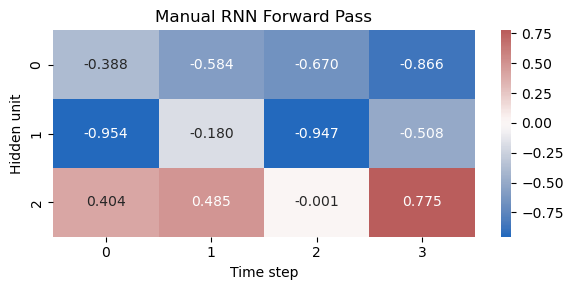

Keras matches manual: True
Max absolute difference: 7.983740768491288e-08
SimpleRNN(64) params: 6208 = 6,208 when embedding_dim=32


In [7]:
np.random.seed(42)
input_size, hidden_size, T = 2, 3, 4
Wxh = np.random.randn(hidden_size, input_size) * .5
Whh = np.random.randn(hidden_size, hidden_size) * .5
b = np.random.randn(hidden_size) * .5
x_demo = np.random.randn(T, input_size)
h = np.zeros(hidden_size)
manual_states = []
for t in range(T):
    h = np.tanh(Wxh @ x_demo[t] + Whh @ h + b)
    manual_states.append(h.copy())
    print(f'h({t+1}) =', h)
manual_states = np.asarray(manual_states)
fig, ax = plt.subplots(figsize=(6,3))
sns.heatmap(manual_states.T, annot=True, fmt='.3f', cmap='vlag', center=0, ax=ax)
ax.set(title='Manual RNN Forward Pass', xlabel='Time step', ylabel='Hidden unit')
fig.tight_layout(); fig.savefig(PLOTS/'rnn_forward_heatmap.png', dpi=150); plt.show()

keras_rnn = SimpleRNN(hidden_size, return_sequences=True, use_bias=True)
_ = keras_rnn(tf.zeros((1,T,input_size)))
keras_rnn.set_weights([Wxh.T, Whh.T, b])  # Keras kernel shape is input_size × units
keras_out = keras_rnn(x_demo[None, ...]).numpy()[0]
print('Keras matches manual:', np.allclose(keras_out, manual_states, atol=1e-6))
print('Max absolute difference:', np.max(np.abs(keras_out-manual_states)))
print('SimpleRNN(64) params:', 64*(EMBED_DIM+64+1), '= 6,208 when embedding_dim=32')

| Feature | ANN baseline | RNN |
|---|---|---|
| Input handling | Fixed slots flattened | Token sequence, one step at a time |
| Word order | Position slots, no recurrent memory | Explicitly processes order |
| Weight sharing | No recurrent sharing across positions | Same recurrent weights each step |
| Parameters vs sequence length | Flattened dense layer grows with `MAXLEN` | Cell parameters fixed for a given input/hidden size |
| Earlier words | No recurrent state | Compressed into hidden state, but may be forgotten |
| Typical use | Tabular/fixed feature vectors | Text, speech and time series |

## Task 3 — RNN types and SimpleRNN sentiment model
**Objective:** Demonstrate four sequence mappings and train a many-to-one sentiment classifier.  
**Expected output:** Output shapes, training curves, evaluation metrics and learned embedding examples.

In [8]:
# Output-shape demonstrations
dummy = tf.zeros((4,10,8))
one_to_one = Dense(1)(tf.zeros((4,8)))
one_to_many = Sequential([Input(shape=(8,)), RepeatVector(10), SimpleRNN(16, return_sequences=True)])
many_to_one = SimpleRNN(16, return_sequences=False)
many_to_many = SimpleRNN(16, return_sequences=True)
print('One-to-one:', one_to_one.shape)
print('One-to-many:', one_to_many(tf.zeros((4,8))).shape)
print('Many-to-one:', many_to_one(dummy).shape)
print('Many-to-many:', many_to_many(dummy).shape)

One-to-one: (4, 1)
One-to-many: (4, 10, 16)
Many-to-one: (4, 16)
Many-to-many: (4, 10, 16)


| Type | Example input shape | Output shape | Sequence setting | Example |
|---|---|---|---|---|
| One-to-one | `(batch, features)` | `(batch, 1)` | Not applicable | Tabular classification |
| One-to-many | `(batch, features)` | `(batch, time, units)` | `return_sequences=True` | Image caption generation |
| Many-to-one | `(batch, time, features)` | `(batch, units)` | `False` | **Sentiment analysis**: whole review → one label |
| Many-to-many | `(batch, time, features)` | `(batch, time, units)` | `True` | Token tagging / sequence labelling |

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

SimpleRNN parameter formula: 6208
Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 36s 60ms/step - accuracy: 0.6018 - loss: 0.6545 - val_accuracy: 0.5977 - val_loss: 0.6583
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 33s 59ms/step - accuracy: 0.6658 - loss: 0.6118 - val_accuracy: 0.6325 - val_loss: 0.6263
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 32s 58ms/step - accuracy: 0.7333 - loss: 0.5333 - val_accuracy: 0.7464 - val_loss: 0.5364
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 32s 57ms/step - accuracy: 0.8072 - loss: 0.4272 - val_accuracy: 0.8004 - val_loss: 0.4579
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 32s 58ms/step - accuracy: 0.8455 - loss: 0.3670 - val_accuracy: 0.8082 - val_loss: 0.4449
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 35s 63ms/step - accuracy: 0.7451 - loss: 0.5015 - val_accuracy: 0.6410 - val_loss: 0.6220
Epoch 7/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 40s 72ms/step - accuracy: 0.7281 - loss: 0.5317 - val_accuracy: 0.6622 - val_loss: 0.6164
Epoch 8/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 33s 59ms/step - 

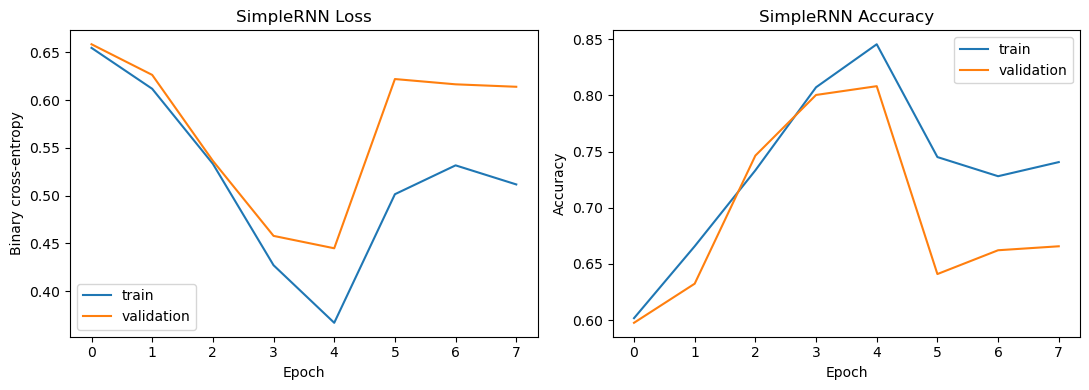


 SimpleRNN 
               precision    recall  f1-score   support

    negative       0.79      0.84      0.82      4940
    positive       0.83      0.78      0.80      4977

    accuracy                           0.81      9917
   macro avg       0.81      0.81      0.81      9917
weighted avg       0.81      0.81      0.81      9917



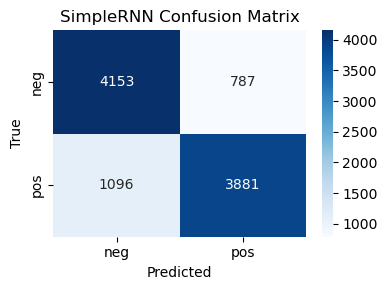

ROC-AUC: 0.8821840791527665 | Test accuracy: 0.8101240294443884


In [9]:
def build_model(cell_type='rnn', units=64, maxlen=MAXLEN, stacked=False, learning_rate=0.001, clipnorm=None):
    cell_type = cell_type.lower()
    opt = Adam(learning_rate=learning_rate, clipnorm=clipnorm) if clipnorm else Adam(learning_rate=learning_rate)
    model = Sequential()
    model.add(Input(shape=(maxlen,)))
    model.add(Embedding(MAX_WORDS, EMBED_DIM, name='embedding'))
    if stacked:
        if cell_type != 'lstm': raise ValueError('Stacked model is defined for LSTM')
        model.add(LSTM(units, return_sequences=True, name='lstm_1'))
        model.add(LSTM(32, name='lstm_2'))
    elif cell_type == 'rnn': model.add(SimpleRNN(units, name='simple_rnn'))
    elif cell_type == 'lstm': model.add(LSTM(units, name='lstm'))
    elif cell_type == 'gru': model.add(GRU(units, name='gru'))
    else: raise ValueError('cell_type must be rnn, lstm, or gru')
    model.add(Dense(1, activation='sigmoid', name='sentiment'))
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return model

def evaluate_model(name, model, history, times):
    prob = model.predict(X_test, batch_size=256, verbose=0).ravel()
    pred = (prob >= .5).astype(int)
    report = classification_report(y_test, pred, target_names=['negative','positive'], output_dict=True, zero_division=0)
    print('\n', name, '\n', classification_report(y_test, pred, target_names=['negative','positive'], zero_division=0))
    cm = confusion_matrix(y_test, pred)
    fig, ax = plt.subplots(figsize=(4,3)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['neg','pos'], yticklabels=['neg','pos'], ax=ax)
    ax.set(title=f'{name} Confusion Matrix', xlabel='Predicted', ylabel='True'); fig.tight_layout()
    fig.savefig(PLOTS/f'confusion_{name.lower().replace(" ","_")}.png', dpi=150); plt.show()
    metrics = {'Parameters': model.count_params(), 'Time per Epoch (s)': float(np.mean(times)),
        'Epochs Trained': len(history.epoch), 'Test Accuracy': accuracy_score(y_test,pred),
        'Precision': report['positive']['precision'], 'Recall': report['positive']['recall'],
        'F1': report['positive']['f1-score'], 'ROC-AUC': roc_auc_score(y_test,prob),
        'probabilities':prob, 'predictions':pred, 'history':history, 'model':model}
    print('ROC-AUC:', metrics['ROC-AUC'], '| Test accuracy:', metrics['Test Accuracy'])
    return metrics

results = {'ANN baseline': ann_metrics}
rnn = build_model('rnn', 64); rnn.summary()
print('SimpleRNN parameter formula:', 64*(EMBED_DIM+64+1))
es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
rnn_hist, rnn_times = timed_fit(rnn, X_train, y_train, epochs=EPOCHS, callbacks=[es])
def plot_history(history, name):
    fig, axes = plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(history.history['loss'], label='train'); axes[0].plot(history.history['val_loss'], label='validation')
    axes[0].set(title=f'{name} Loss', xlabel='Epoch', ylabel='Binary cross-entropy'); axes[0].legend()
    axes[1].plot(history.history['accuracy'], label='train'); axes[1].plot(history.history['val_accuracy'], label='validation')
    axes[1].set(title=f'{name} Accuracy', xlabel='Epoch', ylabel='Accuracy'); axes[1].legend()
    fig.tight_layout(); fig.savefig(PLOTS/f'training_{name.lower().replace(" ","_")}.png', dpi=150); plt.show()
plot_history(rnn_hist, 'SimpleRNN')
results['SimpleRNN'] = evaluate_model('SimpleRNN', rnn, rnn_hist, rnn_times)

### Embedding layer
An embedding maps each integer token ID to a trainable dense vector. The vectors are learned from scratch here—no GloVe, Word2Vec or BERT. Words used in similar contexts may acquire similar vectors, but this is not guaranteed. The embedding matrix shape is `(10000, 32)`.

In [10]:
emb = results['SimpleRNN']['model'].get_layer('embedding').get_weights()[0]
print('Embedding matrix:', emb.shape)
for word in ['good','bad']:
    idx = tokenizer.word_index.get(word)
    if idx is not None and idx < MAX_WORDS: print(word, 'id=',idx,'vector=',emb[idx][:10])

Embedding matrix: (10000, 32)
good id= 49 vector= [ 0.00619246  0.07372948 -0.03131304  0.06580497  0.05221222 -0.05785529
 -0.09345441 -0.04919462  0.01007965  0.08477708]
bad id= 74 vector= [ 0.10070132 -0.12216254  0.18370895 -0.09542007 -0.23549306  0.05434959
  0.10469715  0.12491035 -0.02855688 -0.04711144]


## Task 4 — Backpropagation Through Time and RNN problems
**Objective:** Explain BPTT and inspect gradients across sequence time.  
**Expected output:** Gradient norms and experiments illustrating sequence-length sensitivity and gradient clipping.

BPTT unrolls the RNN into a deep network with shared weights. A loss at the final step propagates backwards through each time step. The gradient for an early state contains a product of Jacobians, each involving the recurrent matrix and the derivative of `tanh`; the gradient for a shared weight sums contributions from all time steps:

\[
\frac{\partial L}{\partial h_1}
=\frac{\partial L}{\partial h_T}\prod_{t=2}^{T}
\left(W_{hh}^{T}\,\mathrm{diag}(1-h_t^2)\right)
\]

If repeated factors are mostly below 1, gradients shrink exponentially (vanishing); if they exceed 1, they can grow exponentially (exploding). Simple RNNs often have limited effective memory, though the exact horizon depends on data and learned weights.

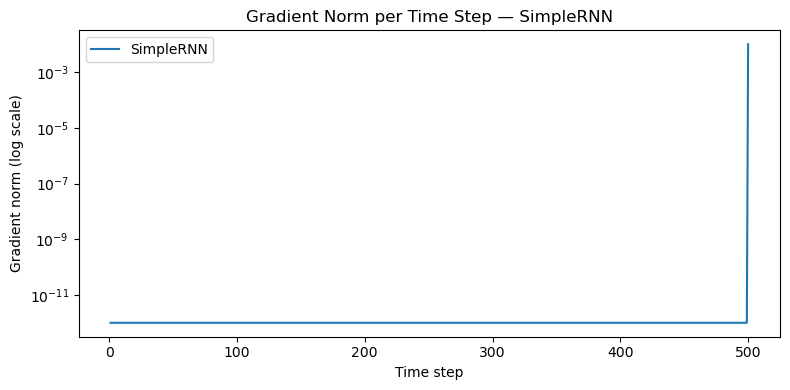

In [11]:
def gradient_norms(model, Xbatch, ybatch):
    # A probe model exposes every recurrent hidden state; the loss still uses the final state.
    base = model.get_layer('embedding')
    cell_layer = next(l for l in model.layers if isinstance(l, (SimpleRNN,LSTM,GRU)))
    dense = model.get_layer('sentiment')
    probe = Sequential([Input(shape=(Xbatch.shape[1],)), base,
                        cell_layer.__class__(cell_layer.units, return_sequences=True, name='probe_cell')])
    # Use the trained recurrent weights for the probe cell
    probe_cell = probe.layers[-1]
    probe_cell.set_weights(cell_layer.get_weights())
    H = probe(Xbatch, training=False)
    with tf.GradientTape() as tape:
        tape.watch(H)
        last = H[:, -1, :]
        logits = dense(last, training=False)
        loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(ybatch, tf.squeeze(logits, axis=-1)))
    grads = tape.gradient(loss, H)
    return tf.reduce_mean(tf.norm(grads, axis=-1), axis=0).numpy()

xb = X_train[:64]; yb = y_train[:64]
rnn_grad = gradient_norms(rnn, xb, yb)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(np.arange(1,MAXLEN+1), rnn_grad+1e-12, label='SimpleRNN')
ax.set_yscale('log'); ax.set(title='Gradient Norm per Time Step — SimpleRNN', xlabel='Time step', ylabel='Gradient norm (log scale)')
ax.legend(); fig.tight_layout(); fig.savefig(PLOTS/'gradient_norms_rnn.png', dpi=150); plt.show()

**Sequence length experiment:** Longer sequences are not automatically better. A simple recurrent cell must propagate useful information through more steps; added tokens can add noise and make optimization harder. This experiment is optional by default because it trains four additional models.

In [12]:
if RUN_EXPENSIVE_EXPERIMENTS:
    length_scores = {}
    for L in [50,100,200,300]:
        tr = pad_sequences(train_seq, maxlen=L, padding='pre', truncating='pre')
        te = pad_sequences(test_seq, maxlen=L, padding='pre', truncating='pre')
        m = build_model('rnn',64,maxlen=L)
        h,_ = timed_fit(m,tr,y_train,epochs=8,callbacks=[EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)],verbose=0)
        length_scores[L] = accuracy_score(y_test,(m.predict(te,batch_size=256,verbose=0).ravel()>=.5).astype(int))
    plt.figure(figsize=(6,4)); plt.plot(list(length_scores),list(length_scores.values()),marker='o')
    plt.title('SimpleRNN Accuracy vs Sequence Length'); plt.xlabel('Sequence length'); plt.ylabel('Test accuracy')
    plt.tight_layout(); plt.savefig(PLOTS/'accuracy_vs_sequence_length.png',dpi=150); plt.show()
    display(pd.Series(length_scores,name='Test accuracy'))
else:
    print('Skipped optional 4-length sweep. Set RUN_EXPENSIVE_EXPERIMENTS=True to run it.')

Skipped optional 4-length sweep. Set RUN_EXPENSIVE_EXPERIMENTS=True to run it.


**Exploding-gradient demo:** a high learning rate may produce unstable loss. Gradient clipping caps gradient norm and can reduce exploding updates, but it does not solve vanishing gradients. Results depend on initialization, data and hardware; do not assume a NaN must occur.

In [13]:
if RUN_EXPENSIVE_EXPERIMENTS:
    high_lr = build_model('rnn',64,learning_rate=.05)
    high_hist,_ = timed_fit(high_lr,X_train,y_train,epochs=5,verbose=0)
    clipped = build_model('rnn',64,learning_rate=.05,clipnorm=1.0)
    clip_hist,_ = timed_fit(clipped,X_train,y_train,epochs=5,verbose=0)
    plt.figure(figsize=(7,4))
    plt.plot(high_hist.history['loss'],label='Adam lr=0.05')
    plt.plot(clip_hist.history['loss'],label='Adam lr=0.05, clipnorm=1.0')
    plt.title('High Learning Rate: With vs Without Gradient Clipping')
    plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.legend()
    plt.tight_layout(); plt.savefig(PLOTS/'gradient_clipping.png',dpi=150); plt.show()
else: print('Skipped optional high-learning-rate clipping demo.')

Skipped optional high-learning-rate clipping demo.


| Problem | Cause | Symptom to inspect | Remedy |
|---|---|---|---|
| Vanishing gradient | Repeated Jacobian factors shrink | Tiny early-step gradient norms | LSTM/GRU gates |
| Exploding gradient | Repeated factors amplify gradients | Loss spikes or NaNs, if observed | Gradient clipping |
| Slow sequential training | Time steps depend on previous state | Epochs take longer than parallel dense operations | Shorter sequences / GPU |
| Short-term memory | Hidden state bottleneck | Long-range cues are missed | Gated cells |

## Task 5 — LSTM (Long Short-Term Memory)
**Objective:** Explain LSTM gates, verify its parameter count, and train/evaluate the model.  
**Expected output:** LSTM metrics, learning curves and gradient comparison.

The LSTM has a cell state \(C_t\), a memory path updated additively, plus gates:
- Forget gate: \(f_t=\sigma(W_f[h_{t-1},x_t]+b_f)\) decides what old memory to keep.
- Input gate: \(i_t=\sigma(W_i[h_{t-1},x_t]+b_i)\) decides what to write.
- Candidate: \(g_t=\tanh(W_g[h_{t-1},x_t]+b_g)\) proposes new content.
- Cell update: \(C_t=f_t*C_{t-1}+i_t*g_t\).
- Output gate: \(o_t=\sigma(W_o[h_{t-1},x_t]+b_o)\) decides what to reveal.
- Hidden state: \(h_t=o_t*\tanh(C_t)\).

The additive cell-state path can preserve gradients when the forget gate stays near 1, giving gradients a less obstructed path across time than a plain RNN.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 344,897 (1.32 MB)

 Trainable params: 344,897 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

LSTM formula: 24832 | Keras recurrent params: 24832
Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 107s 187ms/step - accuracy: 0.7776 - loss: 0.4743 - val_accuracy: 0.6967 - val_loss: 0.5752
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 115s 206ms/step - accuracy: 0.8500 - loss: 0.3534 - val_accuracy: 0.8777 - val_loss: 0.3102
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 124s 223ms/step - accuracy: 0.9059 - loss: 0.2436 - val_accuracy: 0.8803 - val_loss: 0.2970
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 20898s 38s/step - accuracy: 0.9216 - loss: 0.2064 - val_accuracy: 0.8813 - val_loss: 0.3082
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 109s 195ms/step - accuracy: 0.9261 - loss: 0.1961 - val_accuracy: 0.8682 - val_loss: 0.3657
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 132s 237ms/step - accuracy: 0.9299 - loss: 0.1870 - val_accuracy: 0.8697 - val_loss: 0.4070


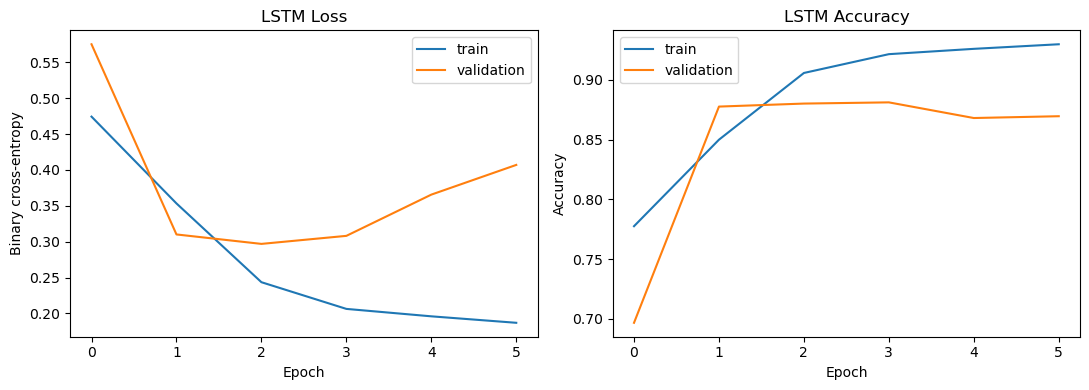


 LSTM 
               precision    recall  f1-score   support

    negative       0.91      0.86      0.88      4940
    positive       0.86      0.91      0.89      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



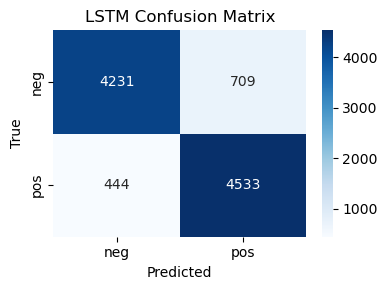

ROC-AUC: 0.9479926284389975 | Test accuracy: 0.8837350005041847


In [14]:
lstm = build_model('lstm',64); lstm.summary()
print('LSTM formula:',4*64*(EMBED_DIM+64+1),'| Keras recurrent params:',lstm.get_layer('lstm').count_params())
lstm_hist,lstm_times = timed_fit(lstm,X_train,y_train,epochs=EPOCHS,callbacks=[EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)])
plot_history(lstm_hist,'LSTM')
results['LSTM'] = evaluate_model('LSTM',lstm,lstm_hist,lstm_times)

### Manual one-step LSTM equations
This NumPy implementation uses concatenated input and previous hidden state. Each gate has its own weights and bias. If \(f_t\approx1\) and \(i_t\approx0\), the cell state is largely preserved.

In [15]:
def sigmoid_np(z): return 1/(1+np.exp(-z))
np.random.seed(42)
d,hsize = 2,3
W = np.random.randn(4*hsize,d+hsize)*.5
bias = np.random.randn(4*hsize)*.5
xseq = np.random.randn(4,d); h=np.zeros(hsize); C=np.zeros(hsize)
rows=[]
for t,x in enumerate(xseq,1):
    z = W @ np.concatenate([h,x]) + bias
    f,i,g,o = np.split(z,4)
    f,i,o = sigmoid_np(f),sigmoid_np(i),sigmoid_np(o); g=np.tanh(g)
    C = f*C + i*g
    h = o*np.tanh(C)
    rows.append({'t':t,'f':np.round(f,3),'i':np.round(i,3),'o':np.round(o,3),'C(t)':np.round(C,3),'h(t)':np.round(h,3)})
display(pd.DataFrame(rows))

,t,f,i,o,C(t),h(t)
0,1,"[0.389, 0.584, 0.134]","[0.156, 0.501, 0.613]","[0.153, 0.726, 0.821]","[0.087, 0.296, -0.459]","[0.013, 0.209, -0.353]"
1,2,"[0.079, 0.684, 0.759]","[0.462, 0.883, 0.761]","[0.15, 0.471, 0.67]","[0.447, 1.078, -0.34]","[0.063, 0.373, -0.22]"
2,3,"[0.445, 0.502, 0.376]","[0.339, 0.604, 0.609]","[0.433, 0.516, 0.633]","[0.241, 0.879, 0.132]","[0.102, 0.364, 0.083]"
3,4,"[0.523, 0.414, 0.726]","[0.637, 0.715, 0.68]","[0.797, 0.29, 0.425]","[-0.214, 0.463, 0.732]","[-0.168, 0.125, 0.265]"


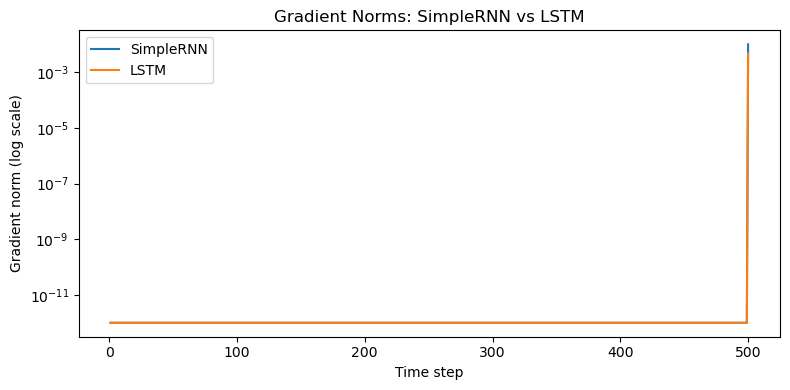

Earliest-step LSTM/RNN gradient ratio: 1.0


In [16]:
lstm_grad = gradient_norms(lstm,xb,yb)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(np.arange(1,MAXLEN+1),rnn_grad+1e-12,label='SimpleRNN')
ax.plot(np.arange(1,MAXLEN+1),lstm_grad+1e-12,label='LSTM')
ax.set_yscale('log'); ax.set(title='Gradient Norms: SimpleRNN vs LSTM',xlabel='Time step',ylabel='Gradient norm (log scale)')
ax.legend(); fig.tight_layout(); fig.savefig(PLOTS/'gradient_norms_rnn_lstm.png',dpi=150); plt.show()
print('Earliest-step LSTM/RNN gradient ratio:', float((lstm_grad[0]+1e-12)/(rnn_grad[0]+1e-12)))

### Stacked LSTM
The first LSTM needs `return_sequences=True` because the second LSTM consumes a full sequence, not a single final vector. More depth adds capacity and compute; it may or may not improve held-out performance.

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 500, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment (Dense)               │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,281 (1.36 MB)

 Trainable params: 357,281 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 226s 397ms/step - accuracy: 0.8110 - loss: 0.4065 - val_accuracy: 0.8871 - val_loss: 0.2868
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 219s 393ms/step - accuracy: 0.8916 - loss: 0.2770 - val_accuracy: 0.8697 - val_loss: 0.3315
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 220s 395ms/step - accuracy: 0.9090 - loss: 0.2378 - val_accuracy: 0.8861 - val_loss: 0.2917
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 220s 394ms/step - accuracy: 0.9306 - loss: 0.1892 - val_accuracy: 0.8866 - val_loss: 0.3260


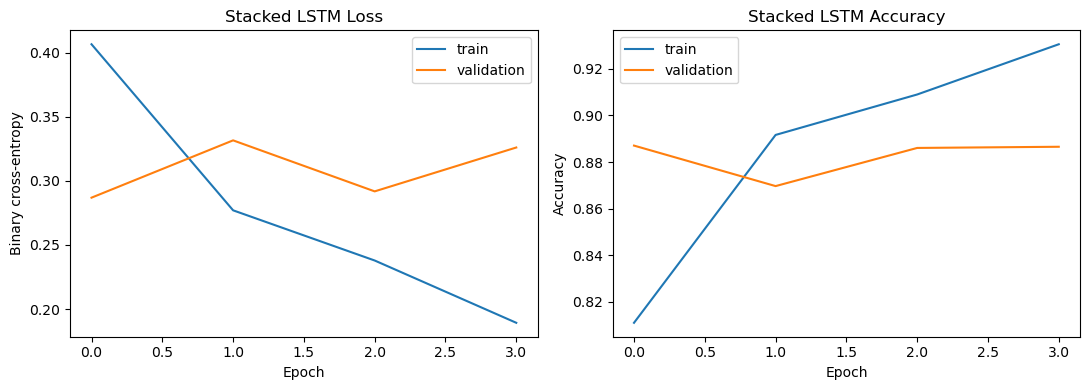


 Stacked LSTM 
               precision    recall  f1-score   support

    negative       0.89      0.88      0.88      4940
    positive       0.88      0.89      0.89      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



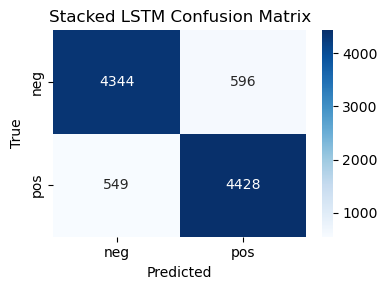

ROC-AUC: 0.9496238161128234 | Test accuracy: 0.8845416960774428


In [17]:
stacked = build_model('lstm',64,stacked=True); stacked.summary()
stack_hist,stack_times = timed_fit(stacked,X_train,y_train,epochs=EPOCHS,callbacks=[EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)])
plot_history(stack_hist,'Stacked LSTM')
results['Stacked LSTM'] = evaluate_model('Stacked LSTM',stacked,stack_hist,stack_times)

## Task 6 — GRU (Gated Recurrent Unit)
**Objective:** Train a GRU, compare its parameter count and gradient flow, and optionally test hidden-unit sensitivity.  
**Expected output:** GRU metrics and three-cell comparison plots.

A GRU has no separate cell state. Its update gate \(z_t=\sigma(W_z[h_{t-1},x_t])\) balances old and candidate state; reset gate \(r_t=\sigma(W_r[h_{t-1},x_t])\) controls how much past information is used to create the candidate \(	ilde h_t=\tanh(W[r_t*h_{t-1},x_t])\). The new state is \(h_t=(1-z_t)*h_{t-1}+z_t*\tilde h_t\). GRU merges the LSTM's forget/input decisions into one update gate.

| Feature | GRU | LSTM |
|---|---|---|
| Gates | 2 (update, reset) | 3 gates (forget, input, output) plus candidate transform |
| Separate cell state | No | Yes |
| Parameters at same hidden size | Usually fewer | Usually more |
| Training speed | Often faster | Often slower |
| Preference | Efficient baseline / limited data or compute | When explicit memory control may help |

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,881 (1.29 MB)

 Trainable params: 338,881 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

GRU reset_after=True formula: 18816 | Keras recurrent params: 18816
Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 134s 235ms/step - accuracy: 0.7680 - loss: 0.4595 - val_accuracy: 0.8722 - val_loss: 0.3122
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 133s 238ms/step - accuracy: 0.8947 - loss: 0.2625 - val_accuracy: 0.8868 - val_loss: 0.2860
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 136s 244ms/step - accuracy: 0.9218 - loss: 0.2104 - val_accuracy: 0.8946 - val_loss: 0.2721
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 134s 240ms/step - accuracy: 0.9390 - loss: 0.1697 - val_accuracy: 0.8815 - val_loss: 0.3458
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 136s 243ms/step - accuracy: 0.9453 - loss: 0.1550 - val_accuracy: 0.8873 - val_loss: 0.3139
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 135s 242ms/step - accuracy: 0.9527 - loss: 0.1319 - val_accuracy: 0.8787 - val_loss: 0.3497


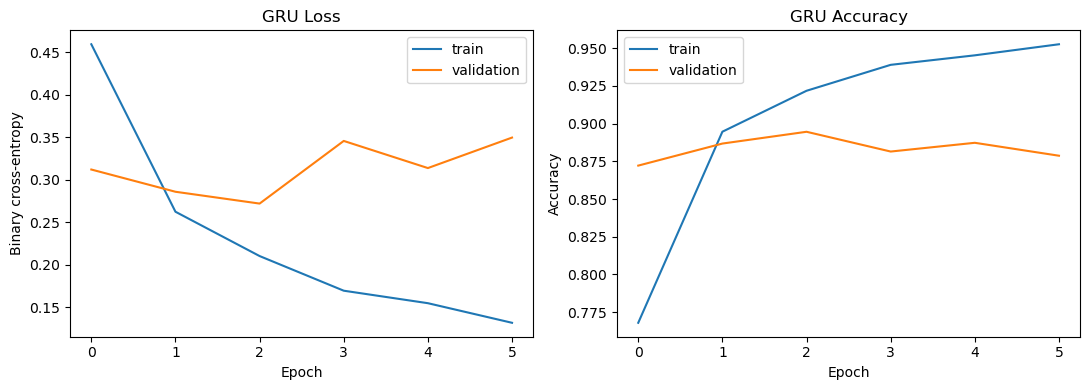


 GRU 
               precision    recall  f1-score   support

    negative       0.90      0.89      0.89      4940
    positive       0.89      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



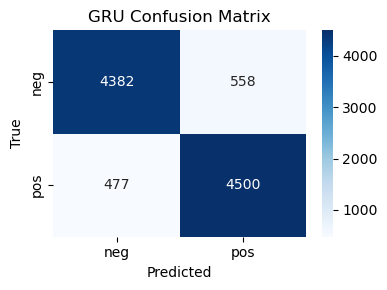

ROC-AUC: 0.9576335759880064 | Test accuracy: 0.8956337602097408


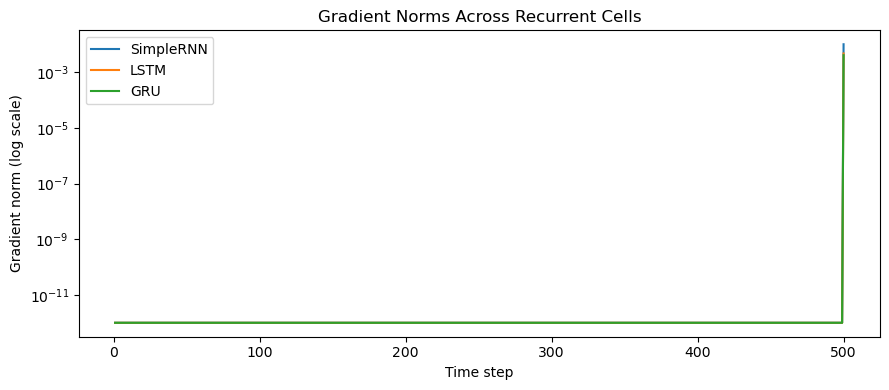

Earliest step norms: {'SimpleRNN': np.float32(0.0), 'LSTM': np.float32(0.0), 'GRU': np.float32(0.0)}


In [18]:
gru = build_model('gru',64); gru.summary()
print('GRU reset_after=True formula:',3*(64*EMBED_DIM+64*64+2*64),'| Keras recurrent params:',gru.get_layer('gru').count_params())
gru_hist,gru_times = timed_fit(gru,X_train,y_train,epochs=EPOCHS,callbacks=[EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)])
plot_history(gru_hist,'GRU')
results['GRU'] = evaluate_model('GRU',gru,gru_hist,gru_times)
gru_grad = gradient_norms(gru,xb,yb)
fig,ax=plt.subplots(figsize=(9,4))
for label,g in [('SimpleRNN',rnn_grad),('LSTM',lstm_grad),('GRU',gru_grad)]:
    ax.plot(np.arange(1,MAXLEN+1),g+1e-12,label=label)
ax.set_yscale('log'); ax.set(title='Gradient Norms Across Recurrent Cells',xlabel='Time step',ylabel='Gradient norm (log scale)')
ax.legend(); fig.tight_layout(); fig.savefig(PLOTS/'gradient_norms_all_cells.png',dpi=150); plt.show()
print('Earliest step norms:', {'SimpleRNN':rnn_grad[0], 'LSTM':lstm_grad[0], 'GRU':gru_grad[0]})

In [19]:
if RUN_EXPENSIVE_EXPERIMENTS:
    sensitivity=[]
    for cell in ['lstm','gru']:
        for units in [32,64,128]:
            m=build_model(cell,units)
            h,times=timed_fit(m,X_train,y_train,epochs=6,callbacks=[EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True)],verbose=0)
            p=m.predict(X_test,batch_size=256,verbose=0).ravel()
            sensitivity.append({'Cell':cell.upper(),'Units':units,'Accuracy':accuracy_score(y_test,(p>=.5).astype(int)),
                                'Parameters':m.count_params()})
    sens=pd.DataFrame(sensitivity); display(sens)
    fig,ax=plt.subplots(figsize=(7,4))
    sns.lineplot(data=sens,x='Units',y='Accuracy',hue='Cell',marker='o',ax=ax)
    ax.set(title='Hidden-Unit Sensitivity: Accuracy',xlabel='Hidden units',ylabel='Test accuracy')
    fig.tight_layout(); fig.savefig(PLOTS/'hidden_unit_accuracy.png',dpi=150); plt.show()
    fig,ax=plt.subplots(figsize=(7,4))
    sns.lineplot(data=sens,x='Units',y='Parameters',hue='Cell',marker='o',ax=ax)
    ax.set(title='Hidden-Unit Sensitivity: Parameters',xlabel='Hidden units',ylabel='Parameter count')
    fig.tight_layout(); fig.savefig(PLOTS/'hidden_unit_parameters.png',dpi=150); plt.show()
else: print('Skipped optional 32/64/128 sensitivity sweep. Set RUN_EXPENSIVE_EXPERIMENTS=True to run it.')

Skipped optional 32/64/128 sensitivity sweep. Set RUN_EXPENSIVE_EXPERIMENTS=True to run it.


## Task 7 — Final comparison, ROC, robustness, error analysis and inference
**Objective:** Compare all trained models, inspect errors, and create a reusable inference function.  
**Expected output:** Results CSV, ROC plot, length-group comparison, misclassified examples and six custom predictions.

In [20]:
metric_cols=['Parameters','Time per Epoch (s)','Epochs Trained','Test Accuracy','Precision','Recall','F1','ROC-AUC']
rows=[]
for name,m in results.items():
    rows.append({'Model':name,**{k:m[k] for k in metric_cols}})
results_df=pd.DataFrame(rows)
display(results_df.style.highlight_max(subset=['Test Accuracy','Precision','Recall','F1','ROC-AUC'],color='#ffcccc'))
results_df.to_csv(PLOTS/'results_table.csv',index=False)
# Also write a plain CSV to the current folder
results_df.to_csv('results_table.csv',index=False)

,Model,Parameters,Time per Epoch (s),Epochs Trained,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,ANN baseline,1344129,8.051932,5,0.845518,0.820584,0.885875,0.851981,0.924476
1,SimpleRNN,326273,34.185326,8,0.810124,0.831405,0.779787,0.804769,0.882184
2,LSTM,344897,3580.762430,6,0.883735,0.864746,0.910790,0.887171,0.947993
3,Stacked LSTM,357281,221.467634,4,0.884542,0.881369,0.889693,0.885511,0.949624
4,GRU,338881,134.705495,6,0.895634,0.889680,0.904159,0.896861,0.957634


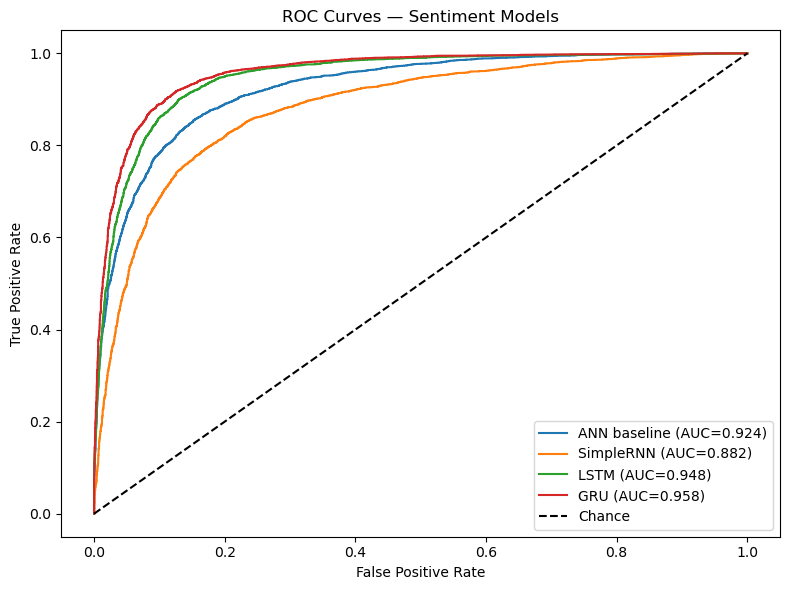

In [21]:
fig,ax=plt.subplots(figsize=(8,6))
for name in ['ANN baseline','SimpleRNN','LSTM','GRU']:
    prob=results[name]['probabilities']
    fpr,tpr,_=roc_curve(y_test,prob)
    ax.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(y_test,prob):.3f})')
ax.plot([0,1],[0,1],'k--',label='Chance')
ax.set(title='ROC Curves — Sentiment Models',xlabel='False Positive Rate',ylabel='True Positive Rate')
ax.legend(); fig.tight_layout(); fig.savefig(PLOTS/'roc_curves.png',dpi=150); plt.show()

ROC curves show the trade-off between true-positive and false-positive rates across thresholds; accuracy gives only one threshold's result. AUC summarizes ranking quality across thresholds.

,Model,Length group,Accuracy,N
0,SimpleRNN,SHORT (<100),0.823156,1261
1,SimpleRNN,MEDIUM (100-250),0.817147,5797
2,SimpleRNN,LONG (>250),0.790136,2859
3,GRU,SHORT (<100),0.896114,1261
4,GRU,MEDIUM (100-250),0.897361,5797
5,GRU,LONG (>250),0.891920,2859


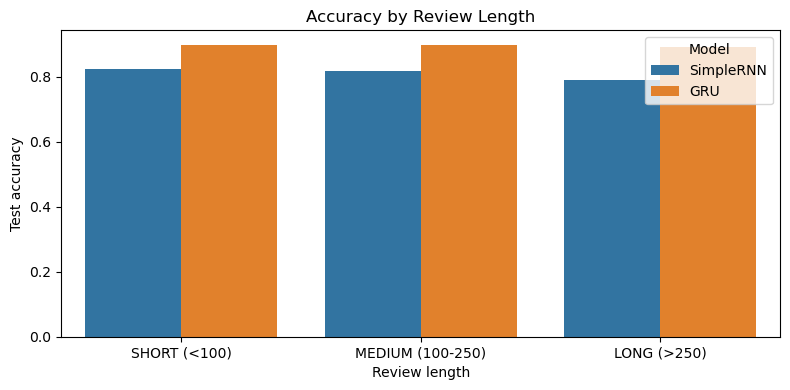

In [22]:
# Compare best of LSTM/GRU with SimpleRNN by length groups using the original cleaned review lengths.
best_name=max(['LSTM','GRU'],key=lambda n:results[n]['ROC-AUC'])
best=results[best_name]
test_idx = np.arange(len(X_test_text))  # test arrays follow the split order
test_lengths = np.array([len(t.split()) for t in X_test_text])
groups=np.where(test_lengths<100,'SHORT (<100)',np.where(test_lengths<=250,'MEDIUM (100-250)','LONG (>250)'))
length_rows=[]
for model_name in ['SimpleRNN',best_name]:
    pred=results[model_name]['predictions']
    for group in ['SHORT (<100)','MEDIUM (100-250)','LONG (>250)']:
        mask=groups==group
        length_rows.append({'Model':model_name,'Length group':group,'Accuracy':accuracy_score(y_test[mask],pred[mask]) if mask.any() else np.nan,'N':int(mask.sum())})
length_df=pd.DataFrame(length_rows); display(length_df)
fig,ax=plt.subplots(figsize=(8,4))
sns.barplot(data=length_df,x='Length group',y='Accuracy',hue='Model',ax=ax)
ax.set(title='Accuracy by Review Length',xlabel='Review length',ylabel='Test accuracy')
fig.tight_layout(); fig.savefig(PLOTS/'accuracy_by_length.png',dpi=150); plt.show()

In [23]:
# Eight errors: four false positives and four false negatives, if available.
best_pred=best['predictions']; best_prob=best['probabilities']
fp=np.where((best_pred==1)&(y_test==0))[0][:4]
fn=np.where((best_pred==0)&(y_test==1))[0][:4]
error_rows=[]
for kind,indices in [('False positive',fp),('False negative',fn)]:
    for i in indices:
        error_rows.append({'Error':kind,'True label':'positive' if y_test[i] else 'negative',
                           'Predicted probability':round(float(best_prob[i]),4),
                           'Cleaned text':X_test_text[i][:1200]})
display(pd.DataFrame(error_rows))

,Error,True label,Predicted probability,Cleaned text
0,False positive,negative,0.9725,i see this movie as a poor tribute to the old ...
1,False positive,negative,0.7484,despite being a huge fan of fred astaire and g...
2,False positive,negative,0.6809,i know that full moon or any other film studio...
3,False positive,negative,0.8889,ok let me again admit that i haven't seen any ...
4,False negative,positive,0.0862,well well roeg touched a bit of a nerve there ...
5,False negative,positive,0.0486,i'm not here to tell you armored is kubrickian...
6,False negative,positive,0.1820,is just as good as the original very nearly ac...
7,False negative,positive,0.0778,saving grace is never riotously funny but it d...


In [24]:
def predict_sentiment(text):
    cleaned=clean_text(text)
    seq=tokenizer.texts_to_sequences([cleaned])
    padded=pad_sequences(seq,maxlen=MAXLEN,padding='pre',truncating='pre')
    prob=float(best['model'].predict(padded,verbose=0)[0,0])
    return {'text':text,'predicted_label':'positive' if prob>=.5 else 'negative',
            'positive_probability':round(prob,4),'negative_probability':round(1-prob,4)}

custom_sentences=[
    'This film is wonderful, moving, and beautifully acted.',
    'A boring, terrible movie with awful dialogue.',
    'This film is not good.',
    'I cannot say this movie was not enjoyable.',
    'Oh fantastic, another two hours of painfully bad acting.',
    'Great!',
    'The story was uneven, but the ending was excellent.'
]
inference_df=pd.DataFrame([predict_sentiment(s) for s in custom_sentences])
display(inference_df)

,text,predicted_label,positive_probability,negative_probability
0,"This film is wonderful, moving, and beautifull...",positive,0.9958,0.0042
1,"A boring, terrible movie with awful dialogue.",negative,0.0012,0.9988
2,This film is not good.,positive,0.7001,0.2999
3,I cannot say this movie was not enjoyable.,negative,0.4938,0.5062
4,"Oh fantastic, another two hours of painfully b...",negative,0.0382,0.9618
5,Great!,positive,0.9978,0.0022
6,"The story was uneven, but the ending was excel...",positive,0.9020,0.0980


### Which Recurrent Cell Should We Use?
Use the measured `results_df` rather than assuming a universal winner:
1. **Accuracy, F1 and ROC-AUC:** rank the cells using the values produced on this held-out test set.
2. **Time and parameters:** SimpleRNN is usually the simplest, GRU often offers a middle ground, and LSTM typically has more parameters.
3. **Long reviews:** inspect the grouped bar chart; do not assume the best overall model is best on every length group.
4. **Recommendation:** for a practical production baseline, choose the model with the best balance of validation/test quality, stability and latency. GRU is a reasonable efficiency-first candidate; prefer LSTM if it materially improves the measured quality enough to justify its cost.
5. **Limitations:** embeddings are learned only from this dataset, so they lack pretrained external knowledge; these models are one-directional and cannot use future context while reading each token.

## Submission quality checks and exports
**Objective:** Save key outputs and list dependencies. **Expected output:** `plots/` figures, `results_table.csv`, and a ready-to-copy requirements list.

Before submission: run **Kernel → Restart & Run All**. This notebook uses the provided raw Kaggle CSV; ensure the dataset is placed beside the notebook. Export HTML from Jupyter after the run succeeds.

In [25]:
requirements = '''tensorflow
scikit-learn
pandas
numpy
matplotlib
seaborn
'''
Path('requirements.txt').write_text(requirements,encoding='utf-8')
print('Wrote requirements.txt')
print('Plots currently created:', sorted(p.name for p in PLOTS.glob('*')))
print('Best model by ROC-AUC:', max(results, key=lambda n: results[n]['ROC-AUC']))

Wrote requirements.txt
Plots currently created: ['accuracy_by_length.png', 'confusion_gru.png', 'confusion_lstm.png', 'confusion_simplernn.png', 'confusion_stacked_lstm.png', 'gradient_norms_all_cells.png', 'gradient_norms_rnn.png', 'gradient_norms_rnn_lstm.png', 'length_by_sentiment.png', 'length_distribution.png', 'results_table.csv', 'rnn_forward_heatmap.png', 'roc_curves.png', 'training_gru.png', 'training_lstm.png', 'training_simplernn.png', 'training_stacked_lstm.png']
Best model by ROC-AUC: GRU
